# Real-World Dataset Analysis Project
## Survival Patterns in the Titanic Passenger Data
**Task 3 – Yuva Intern | AI/ML Research Specialist Internship**

**Workflow:** dataset selection → exploration → cleaning → EDA → visualization → insights and recommendations.

## 1. Dataset Selection & Context
**Dataset:** Titanic passenger manifest (891 passengers) – a widely used, openly available real-world dataset originally compiled from historical records of the RMS Titanic (1912) and distributed through Kaggle / the Data Science Dojo public datasets repository.

**Analytical context:** On 15 April 1912 the Titanic sank with a lifeboat capacity far below the number of people on board. The analytical question is *which passenger characteristics were associated with survival?* The same approach (segmenting outcomes by customer/patient/asset attributes) is used in churn analysis, risk scoring and safety analytics.

**Objectives**
1. Understand the structure and quality of the data.
2. Clean it with defensible techniques.
3. Identify which factors (sex, class, age, family size, fare, port) relate to survival.
4. Communicate findings with visualizations and recommendations.

**Expected outcome:** women and higher-class passengers had higher survival rates ("women and children first" and class-based access to lifeboats).

| Column | Meaning |
|---|---|
| PassengerId | Row id |
| Survived | 0 = No, 1 = Yes (target) |
| Pclass | Ticket class (1 = upper, 2 = middle, 3 = lower) |
| Name, Sex, Age | Passenger details |
| SibSp / Parch | Siblings-spouses / parents-children aboard |
| Ticket, Fare, Cabin | Ticket number, fare paid, cabin |
| Embarked | Port: C = Cherbourg, Q = Queenstown, S = Southampton |

In [1]:
import json, os, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
sns.set_theme(style="whitegrid", palette="deep")
os.makedirs("images", exist_ok=True)
M = {}   # key metrics, exported for the written report

def save(name):
    plt.tight_layout(); plt.savefig(f"images/{name}.png", dpi=130); plt.show()

URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
try:
    raw = pd.read_csv("data/titanic_raw.csv")      # local copy included in the repo
except FileNotFoundError:
    raw = pd.read_csv(URL); raw.to_csv("data/titanic_raw.csv", index=False)
raw.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Explore the Dataset

In [2]:
print("Shape:", raw.shape); raw.info()

Shape: (891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [3]:
print(raw.describe().round(2))
print("\nCategorical summary:")
print(raw[["Sex", "Embarked", "Pclass"]].apply(lambda s: s.value_counts(dropna=False).to_dict()))

       PassengerId  Survived  Pclass     Age   SibSp   Parch    Fare
count       891.00    891.00  891.00  714.00  891.00  891.00  891.00
mean        446.00      0.38    2.31   29.70    0.52    0.38   32.20
std         257.35      0.49    0.84   14.53    1.10    0.81   49.69
min           1.00      0.00    1.00    0.42    0.00    0.00    0.00
25%         223.50      0.00    2.00   20.12    0.00    0.00    7.91
50%         446.00      0.00    3.00   28.00    0.00    0.00   14.45
75%         668.50      1.00    3.00   38.00    1.00    0.00   31.00
max         891.00      1.00    3.00   80.00    8.00    6.00  512.33

Categorical summary:
Sex                  {'male': 577, 'female': 314}
Embarked    {'S': 644, 'C': 168, 'Q': 77, nan: 2}
Pclass                   {3: 491, 1: 216, 2: 184}
dtype: object


In [4]:
miss = raw.isna().sum().to_frame("missing"); miss["pct"] = (miss["missing"] / len(raw) * 100).round(1)
print(miss[miss.missing > 0])
print("\nExact duplicate rows:", raw.duplicated().sum())
print("Duplicate PassengerIds:", raw["PassengerId"].duplicated().sum())
print("Rows sharing a ticket (family/group bookings, legitimate):", raw["Ticket"].duplicated(keep=False).sum())
print("Fares equal to 0:", (raw["Fare"] == 0).sum())
M.update(rows=len(raw), cols=raw.shape[1], miss_age=int(raw.Age.isna().sum()), miss_cabin=int(raw.Cabin.isna().sum()),
         miss_emb=int(raw.Embarked.isna().sum()), dups=int(raw.duplicated().sum()), zero_fare=int((raw.Fare == 0).sum()))

          missing   pct
Age           177  19.9
Cabin         687  77.1
Embarked        2   0.2

Exact duplicate rows: 0
Duplicate PassengerIds: 0
Rows sharing a ticket (family/group bookings, legitimate): 344
Fares equal to 0: 15


**Initial findings:** Age has 177 missing values (19.9%), Cabin 687 (77.1%) and Embarked 2. There are no exact duplicate rows or duplicate IDs. Shared ticket numbers are group/family bookings and are **not** duplicates. Several passengers have a fare of 0, which is unusual and is examined below.

## 3. Clean & Preprocess

### 3.1 Inconsistent data – extract and standardise titles from names

In [5]:
df = raw.copy()
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
print(df["Title"].value_counts().to_dict())

title_map = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs", "Lady": "Rare", "the Countess": "Rare", "Sir": "Rare",
             "Don": "Rare", "Dona": "Rare", "Jonkheer": "Rare", "Capt": "Rare", "Col": "Rare", "Major": "Rare",
             "Dr": "Rare", "Rev": "Rare"}
df["Title"] = df["Title"].replace(title_map)
print("\nStandardised:", df["Title"].value_counts().to_dict())

{'Mr': 517, 'Miss': 182, 'Mrs': 125, 'Master': 40, 'Dr': 7, 'Rev': 6, 'Major': 2, 'Mlle': 2, 'Col': 2, 'Don': 1, 'Mme': 1, 'Ms': 1, 'Lady': 1, 'Sir': 1, 'Capt': 1, 'the Countess': 1, 'Jonkheer': 1}

Standardised: {'Mr': 517, 'Miss': 185, 'Mrs': 126, 'Master': 40, 'Rare': 23}


### 3.2 Missing values

In [6]:
# Age: median by Title x Pclass (more accurate than one global median)
M["age_median_global"] = float(raw.Age.median())
df["Age_missing"] = df["Age"].isna()
df["Age"] = df["Age"].fillna(df.groupby(["Title", "Pclass"])["Age"].transform("median"))
df["Age"] = df["Age"].fillna(df["Age"].median())              # fallback for any empty group

# Embarked: only 2 missing -> mode
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Cabin: too sparse to impute -> keep only the deck letter, 'Unknown' if absent
df["Deck"] = df["Cabin"].str[0].fillna("Unknown")
df["Has_cabin"] = df["Cabin"].notna().astype(int)
df = df.drop(columns="Cabin")
print("Remaining missing values:", int(df.isna().sum().sum()))

Remaining missing values: 0


### 3.3 Incorrect data types

In [7]:
for col in ["Survived", "Pclass", "Sex", "Embarked", "Deck", "Title"]:
    df[col] = df[col].astype("category")
df["Age"] = df["Age"].round(1)
df.dtypes

PassengerId       int64
Survived       category
Pclass         category
Name                str
Sex            category
Age             float64
SibSp             int64
Parch             int64
Ticket              str
Fare            float64
Embarked       category
Title          category
Age_missing        bool
Deck           category
Has_cabin         int64
dtype: object

### 3.4 Duplicates

In [8]:
before = len(df)
df = df.drop_duplicates().drop_duplicates(subset="PassengerId")
print("Rows removed:", before - len(df), "(none existed – verified rather than assumed)")

Rows removed: 0 (none existed – verified rather than assumed)


### 3.5 Outliers – IQR rule

In [9]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i))

for col in ["Age", "Fare", "SibSp", "Parch"]:
    print(f"{col:<6} outliers: {iqr_outliers(df[col]).sum():>3} ({iqr_outliers(df[col]).mean():.1%})")
print("\nHighest fares:", sorted(df.Fare, reverse=True)[:4])
print("Zero-fare passengers by Pclass:", df[df.Fare == 0]["Pclass"].value_counts().to_dict())
M["fare_outliers"] = int(iqr_outliers(df.Fare).sum()); M["age_outliers"] = int(iqr_outliers(df.Age).sum())

Age    outliers:  22 (2.5%)
Fare   outliers: 116 (13.0%)
SibSp  outliers:  46 (5.2%)
Parch  outliers: 213 (23.9%)

Highest fares: [512.3292, 512.3292, 512.3292, 263.0]
Zero-fare passengers by Pclass: {2: 6, 1: 5, 3: 4}


**Decision:** The very high fares (up to £512) belong to genuine first-class suites and the zero fares are possibly complimentary or special-arrangement tickets, so they are **kept**. Because Fare is heavily right-skewed, a log transform (`log1p`) is used for visualization and correlation. Ages up to 80 are plausible and also kept.

In [10]:
df["Fare_log"] = np.log1p(df["Fare"])
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
df["AgeGroup"] = pd.cut(df["Age"], [0, 12, 18, 35, 60, 100], labels=["Child (0-12)", "Teen (13-18)", "Adult (19-35)", "Middle (36-60)", "Senior (60+)"])
df["Survived_n"] = df["Survived"].astype(int)
df.to_csv("data/titanic_clean.csv", index=False)
print(df.shape); df.head()

(891, 20)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Title,Age_missing,Deck,Has_cabin,Fare_log,FamilySize,IsAlone,AgeGroup,Survived_n
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,Mr,False,Unknown,0,2.110213,2,0,Adult (19-35),0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,Mrs,False,C,1,4.280593,2,0,Middle (36-60),1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,Miss,False,Unknown,0,2.188856,1,1,Adult (19-35),1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,Mrs,False,C,1,3.990834,2,0,Adult (19-35),1
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,Mr,False,Unknown,0,2.202765,1,1,Adult (19-35),0


## 4. Exploratory Data Analysis

In [11]:
overall = df.Survived_n.mean()
print(f"Overall survival rate: {overall:.1%} ({df.Survived_n.sum()} of {len(df)})")
M["overall"] = overall; M["survivors"] = int(df.Survived_n.sum())

def rate(col): return df.groupby(col, observed=True)["Survived_n"].agg(["count", "mean"]).rename(columns={"mean": "survival_rate"}).round(3)
for col in ["Sex", "Pclass", "AgeGroup", "Embarked", "IsAlone"]:
    print(f"\n--- {col} ---"); print(rate(col))

Overall survival rate: 38.4% (342 of 891)

--- Sex ---
        count  survival_rate
Sex                         
female    314          0.742
male      577          0.189

--- Pclass ---
        count  survival_rate
Pclass                      
1         216          0.630
2         184          0.473
3         491          0.242

--- AgeGroup ---
                count  survival_rate
AgeGroup                            
Child (0-12)       73          0.575
Teen (13-18)      103          0.476
Adult (19-35)     469          0.330
Middle (36-60)    224          0.406
Senior (60+)       22          0.227

--- Embarked ---
          count  survival_rate
Embarked                      
C           168          0.554
Q            77          0.390
S           646          0.339

--- IsAlone ---
         count  survival_rate
IsAlone                      
0          354          0.506
1          537          0.304


In [12]:
print(rate("FamilySize"))
print("\nSex x Pclass survival rate:")
sp = df.pivot_table(index="Sex", columns="Pclass", values="Survived_n", aggfunc="mean", observed=True).round(3); print(sp)
M["sex"] = rate("Sex")["survival_rate"].to_dict(); M["pclass"] = rate("Pclass")["survival_rate"].to_dict()
M["agegrp"] = rate("AgeGroup")["survival_rate"].to_dict(); M["emb"] = rate("Embarked")["survival_rate"].to_dict()
M["alone"] = rate("IsAlone")["survival_rate"].to_dict(); M["fam"] = rate("FamilySize")["survival_rate"].to_dict()
M["sexclass"] = {f"{s}-{c}": float(sp.loc[s, c]) for s in sp.index for c in sp.columns}

            count  survival_rate
FamilySize                      
1             537          0.304
2             161          0.553
3             102          0.578
4              29          0.724
5              15          0.200
6              22          0.136
7              12          0.333
8               6          0.000
11              7          0.000

Sex x Pclass survival rate:
Pclass      1      2      3
Sex                        
female  0.968  0.921  0.500
male    0.369  0.157  0.135


In [13]:
print(df.groupby("Survived", observed=True)[["Age", "Fare", "FamilySize"]].agg(["mean", "median"]).round(2))
num = df[["Survived_n", "Pclass", "Age", "SibSp", "Parch", "Fare_log", "FamilySize", "IsAlone", "Has_cabin"]].copy()
num["Pclass"] = num["Pclass"].astype(int)
corr = num.corr().round(2); print(corr["Survived_n"].sort_values())
M["corr"] = corr["Survived_n"].drop("Survived_n").to_dict()

            Age          Fare        FamilySize       
           mean median   mean median       mean median
Survived                                              
0         29.80   26.0  22.12   10.5       1.88    1.0
1         28.06   27.5  48.40   26.0       1.94    2.0
Pclass       -0.34
IsAlone      -0.20
Age          -0.06
SibSp        -0.04
FamilySize    0.02
Parch         0.08
Has_cabin     0.32
Fare_log      0.33
Survived_n    1.00
Name: Survived_n, dtype: float64


### Statistical significance (chi-square tests of independence)

In [14]:
for col in ["Sex", "Pclass", "Embarked", "IsAlone"]:
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df[col], df["Survived"]))
    print(f"{col:<9} chi2 = {chi2:7.2f}  p = {p:.2e}  ->", "significant" if p < 0.05 else "not significant")
    M.setdefault("chi", {})[col] = [float(chi2), float(p)]

# Age: survivors vs non-survivors (Mann-Whitney, since age is not normal)
u, p = stats.mannwhitneyu(df[df.Survived_n == 1].Age, df[df.Survived_n == 0].Age)
print(f"Age  Mann-Whitney U p = {p:.3f}")
M["age_p"] = float(p)

Sex       chi2 =  260.72  p = 1.20e-58  -> significant
Pclass    chi2 =  102.89  p = 4.55e-23  -> significant
Embarked  chi2 =   25.96  p = 2.30e-06  -> significant
IsAlone   chi2 =   36.00  p = 1.97e-09  -> significant
Age  Mann-Whitney U p = 0.216


## 5. Data Visualizations

### 5.1 Bar chart – survival rate by sex and class

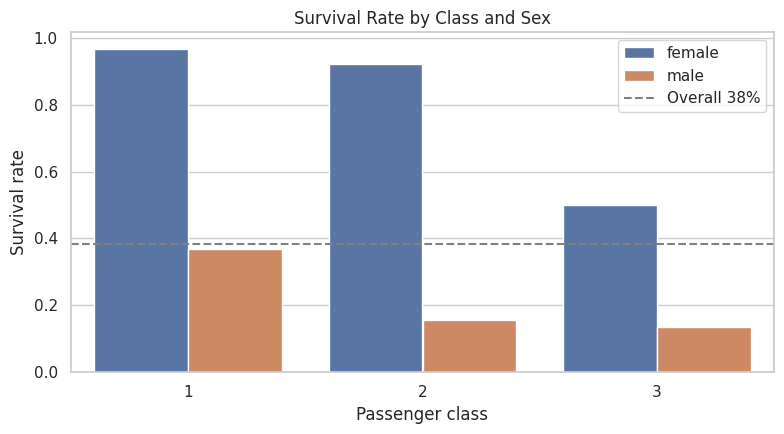

In [15]:
plt.figure(figsize=(8, 4.5))
sns.barplot(data=df, x="Pclass", y="Survived_n", hue="Sex", errorbar=None)
plt.axhline(overall, ls="--", c="gray", label=f"Overall {overall:.0%}")
plt.title("Survival Rate by Class and Sex"); plt.ylabel("Survival rate"); plt.xlabel("Passenger class"); plt.legend()
save("01_bar_survival_sex_class")

### 5.2 Histogram – age distribution by outcome

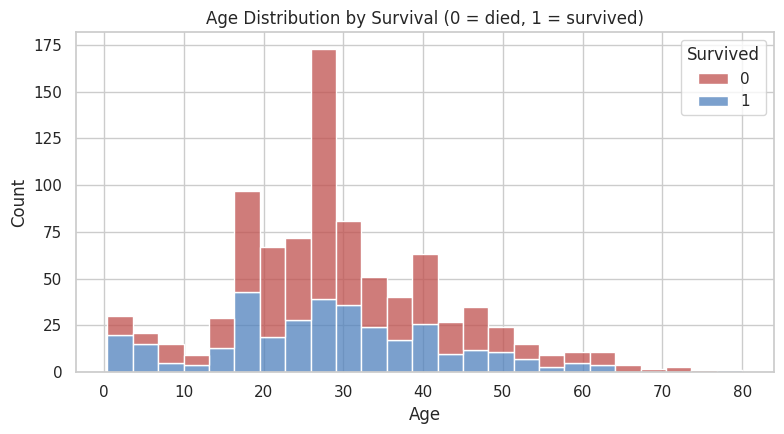

In [16]:
plt.figure(figsize=(8, 4.5))
sns.histplot(data=df, x="Age", hue="Survived", bins=25, multiple="stack", palette={0: "#c0504d", 1: "#4f81bd"})
plt.title("Age Distribution by Survival (0 = died, 1 = survived)")
save("02_hist_age")

### 5.3 Line chart – survival rate across age

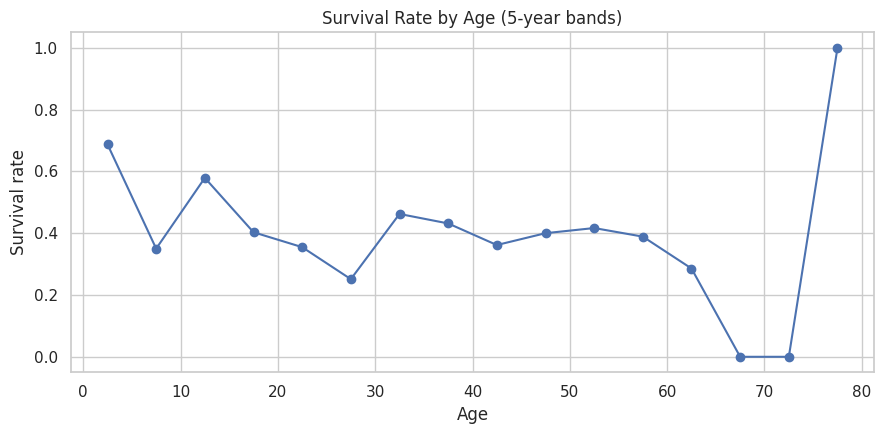

In [17]:
bins = pd.cut(df["Age"], range(0, 85, 5))
line = df.groupby(bins, observed=True)["Survived_n"].mean()
plt.figure(figsize=(9, 4.5)); plt.plot([i.mid for i in line.index], line.values, marker="o")
plt.title("Survival Rate by Age (5-year bands)"); plt.xlabel("Age"); plt.ylabel("Survival rate")
save("03_line_age_survival")

### 5.3 Scatter plot – age vs fare

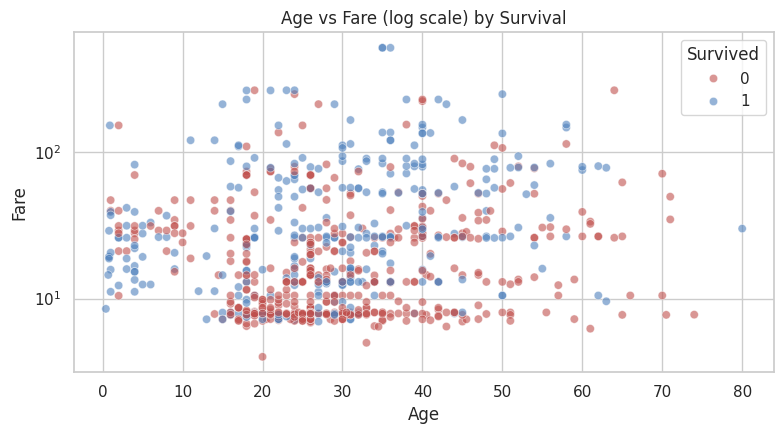

In [18]:
plt.figure(figsize=(8, 4.5))
sns.scatterplot(data=df, x="Age", y="Fare", hue="Survived", alpha=0.6, palette={0: "#c0504d", 1: "#4f81bd"})
plt.yscale("log"); plt.title("Age vs Fare (log scale) by Survival")
save("04_scatter_age_fare")

### 5.4 Box plot – fare by class

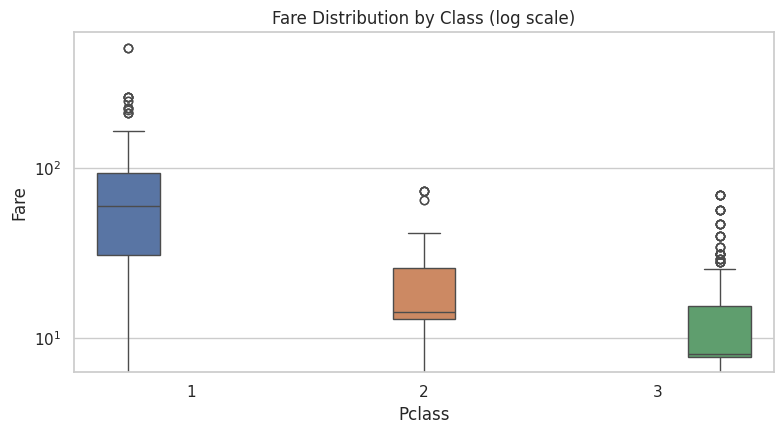

In [19]:
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df, x="Pclass", y="Fare", hue="Pclass", legend=False); plt.yscale("log")
plt.title("Fare Distribution by Class (log scale)")
save("05_box_fare_class")

### 5.5 Heatmap – correlations

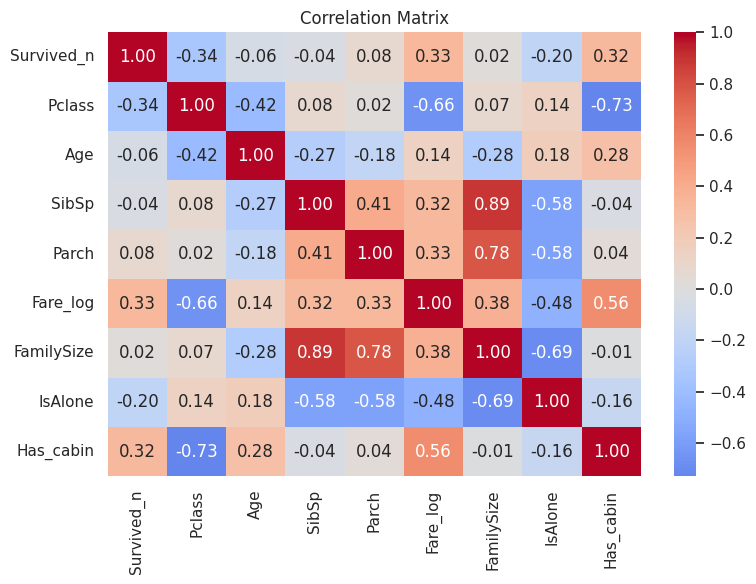

In [20]:
plt.figure(figsize=(8, 6)); sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Matrix")
save("06_heatmap_corr")

### 5.6 Count plot – family size and survival

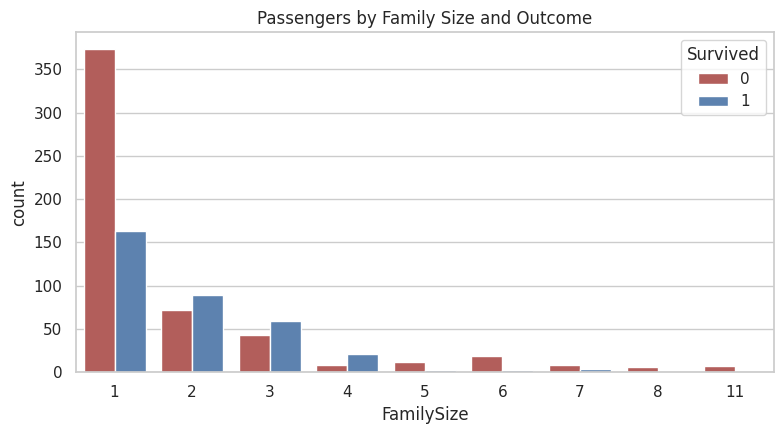

In [21]:
plt.figure(figsize=(8, 4.5)); sns.countplot(data=df, x="FamilySize", hue="Survived", palette={0: "#c0504d", 1: "#4f81bd"})
plt.title("Passengers by Family Size and Outcome")
save("07_count_family")

## 6. Insights & Interpretation

In [22]:
s = M["sex"]; p = M["pclass"]
print(f"1. SEX: {s['female']:.0%} of women survived vs {s['male']:.0%} of men – the strongest single factor.")
print(f"2. CLASS: survival fell from {p[1]:.0%} (1st) to {p[2]:.0%} (2nd) to {p[3]:.0%} (3rd).")
print(f"3. COMBINED: 1st/2nd-class women survived at {M['sexclass']['female-1']:.0%}/{M['sexclass']['female-2']:.0%}, third-class women {M['sexclass']['female-3']:.0%}; third-class men only {M['sexclass']['male-3']:.0%}.")
print(f"4. AGE: children aged 0-12 survived at {M['agegrp']['Child (0-12)']:.0%}; age shows a weak overall link (Mann-Whitney p = {M['age_p']:.2f}).")
print(f"5. FAMILY: passengers travelling alone survived at {M['alone'][1]:.0%} vs {M['alone'][0]:.0%} with family; very large families (5+) fared worst.")
print(f"6. PORT: Cherbourg {M['emb']['C']:.0%} vs Southampton {M['emb']['S']:.0%} – partly explained by Cherbourg having more first-class passengers (51% vs 20% at Southampton).")
print(f"7. FARE: higher fares correlate with survival (r = {M['corr']['Fare_log']:.2f}) – again reflecting class and deck position.")

1. SEX: 74% of women survived vs 19% of men – the strongest single factor.
2. CLASS: survival fell from 63% (1st) to 47% (2nd) to 24% (3rd).
3. COMBINED: 1st/2nd-class women survived at 97%/92%, third-class women 50%; third-class men only 14%.
4. AGE: children aged 0-12 survived at 57%; age shows a weak overall link (Mann-Whitney p = 0.22).
5. FAMILY: passengers travelling alone survived at 30% vs 51% with family; very large families (5+) fared worst.
6. PORT: Cherbourg 55% vs Southampton 34% – partly explained by Cherbourg having more first-class passengers (51% vs 20% at Southampton).
7. FARE: higher fares correlate with survival (r = 0.33) – again reflecting class and deck position.


### Conclusions
Survival was strongly structured by **sex, class and age group**, and these effects combine. All chi-square tests for sex, class, port and travelling alone are significant (p < 0.05).

### Limitations
- The analysis is **observational**: correlations do not prove cause (for example, Embarked is a proxy for class).
- 20% of ages were imputed, so age-based findings carry extra uncertainty.
- The data covers 891 of about 2,200 people on board, and the crew is largely missing.

### Recommendations (transferable to real organisations)
1. **Safety planning:** evacuation procedures must be equitable – access to safety equipment should not depend on class or location of cabin.
2. **Data collection:** record complete, validated attributes (age, location on the ship) at source, since 77% of cabin data was lost.
3. **Next step – modelling:** build a classification model (logistic regression / random forest) using Sex, Pclass, Age, Title and FamilySize, evaluated with cross-validation.
4. **Communicate with context:** report rates together with group sizes so that small groups are not over-interpreted.

In [23]:
json.dump(M, open("data/metrics.json", "w"), indent=1, default=float)
print("Saved metrics.json")

Saved metrics.json
